# 1. Circuiti fotonici e interferometri universali

Notebook a corredo delle sezioni 3 e 6 della tesina *Simulazione di un esperimento di
computazione quantistica fotonica*.

Si costruiscono con Perceval i componenti elementari (permutazione, beam splitter
regolabile) e le reti universali a tre e a quattro modi, verificando in ciascun caso il
conteggio dei parametri e la matrice unitaria risultante.

Nel codice i modi sono numerati a partire da zero, come richiede la libreria; nel testo
della tesina e nelle figure la numerazione parte da uno.

In [1]:
import perceval as pcvl
import numpy as np
from perceval.components import PS, BS, PERM

print("Perceval", pcvl.__version__)

Perceval 1.2.4


In [2]:
def probabilita(U, cifre=3):
    """Matrice |U_ij|^2: probabilita' che un fotone entrato nel modo j esca dal modo i."""
    return pcvl.Matrix(np.round(abs(np.array(U))**2, cifre))

## 1.1 Il componente PERM: permutare i modi

Un beam splitter agisce necessariamente su modi adiacenti. Per far interferire modi non
contigui occorre riordinare le guide, e a questo serve `PERM`, che scambia i modi senza
mescolarne le ampiezze: la sua matrice ha un solo elemento unitario per riga e per colonna.

PERM
PERM([2, 0, 1])


<IPython.core.display.Math object>

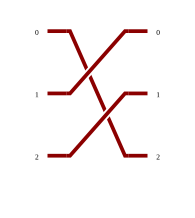

In [3]:
perm = PERM([2, 0, 1])

print(perm.name)
print(perm.describe())
pcvl.pdisplay(perm.definition())
pcvl.pdisplay(perm)

## 1.2 Beam splitter regolabile

Il blocco elementare e' un beam splitter a riflettivita' variabile, realizzato
come due beam splitter bilanciati con una fase interna $\theta$ interposta, seguiti da una
fase esterna $\varphi$:

$$M_C = \begin{pmatrix} e^{i\varphi} & 0 \\ 0 & 1 \end{pmatrix}
        \, BS \begin{pmatrix} e^{i\theta} & 0 \\ 0 & 1 \end{pmatrix} BS .$$

La fase interna $\theta$ regola la ripartizione fra le due uscite, la fase esterna
$\varphi$ la fase relativa. Con questa costruzione la probabilita' che il fotone resti nel
proprio modo vale $\sin^2(\theta/2)$.

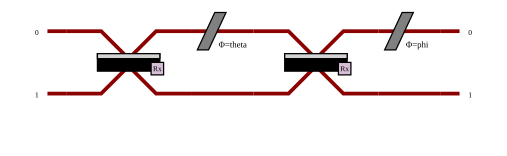

In [4]:
c = pcvl.Circuit(2)
c.add(0, pcvl.BS())                        # BS 50:50 fisso
c.add(0, pcvl.PS(phi=pcvl.P("theta")))     # fase interna: regola la ripartizione
c.add(0, pcvl.BS())                        # BS 50:50 fisso
c.add(0, pcvl.PS(phi=pcvl.P("phi")))       # fase esterna: a valle del blocco

pcvl.pdisplay_to_file(c, "blocco_regolabile.pdf")
pcvl.pdisplay(c)

## 1.3 La matrice del blocco al variare di $\theta$ e $\varphi$

Con $\theta = \pi/2$ il blocco e' bilanciato; con $\theta = \pi$ il fotone resta
interamente nel proprio modo.

In [5]:
def unitaria(theta, phi):
    for p in c.get_parameters():
        p.set_value(float(theta) if p.name == "theta" else float(phi))
    return c.compute_unitary()

U = unitaria(np.pi/2, np.pi/8)  # modificando phi, la probabilità resta inalterata
pcvl.pdisplay(U, precision=1e-3)
pcvl.pdisplay(probabilita(U))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [6]:
# verifica della legge sin^2(theta/2) sul blocco costruito a mano
print(f"{'theta':>8} {'|U00|^2':>10} {'sin^2(theta/2)':>16}")
for th in [0.0, np.pi/3, np.pi/2, 2.0, np.pi]:
    U = np.array(unitaria(th, 0.0))
    print(f"{th:8.4f} {abs(U[0,0])**2:10.4f} {np.sin(th/2)**2:16.4f}")

   theta    |U00|^2   sin^2(theta/2)
  0.0000     0.0000           0.0000
  1.0472     0.2500           0.2500
  1.5708     0.5000           0.5000
  2.0000     0.7081           0.7081
  3.1416     1.0000           1.0000


## 1.4 Convenzioni

Perceval mette a disposizione anche il beam splitter parametrico `BS(theta=...)`, che si
userà nelle celle seguenti perché più compatto. La sua convenzione non coincide però con
quella del blocco costruito precedentemente: indicando con $\Theta$ il suo parametro, la probabilità
che il fotone resti nel proprio modo vale $\cos^2(\Theta/2)$ e non
$\sin^2(\theta/2)$.

Le due descrizioni coincidono per

$$\Theta = \pi - \theta ,$$

come la cella seguente verifica.

In [7]:
print(f"{'theta':>8} {'blocco a mano':>15} {'BS(Theta=pi-theta)':>20}")
for th in [0.0, np.pi/3, np.pi/2, 2.0, np.pi]:
    a = abs(np.array(unitaria(th, 0.0))[0, 0])**2
    b = abs(np.array(pcvl.BS(theta=np.pi - th).compute_unitary())[0, 0])**2
    print(f"{th:8.4f} {a:15.4f} {b:20.4f}")

   theta   blocco a mano   BS(Theta=pi-theta)
  0.0000          0.0000               0.0000
  1.0472          0.2500               0.2500
  1.5708          0.5000               0.5000
  2.0000          0.7081               0.7081
  3.1416          1.0000               1.0000


## 1.5 Rete universale a tre modi



9 parametri liberi


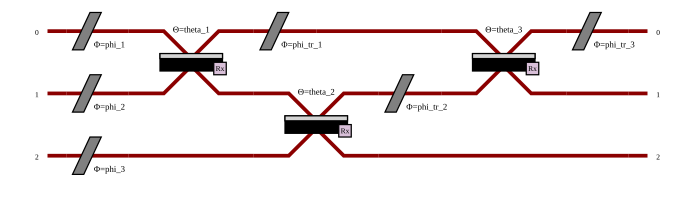

In [8]:
P = pcvl.P
d = pcvl.Circuit(3)

# le 3 fasi iniziali, una per modo
for k in range(3):
    d.add(k, pcvl.PS(P(f"phi_{k+1}")))

# blocco A: modi 0-1
d.add(0, pcvl.BS(theta=P("theta_1")))
d.add(0, pcvl.PS(P("phi_tr_1")))       # fase esterna, a valle del blocco

# blocco B: modi 1-2
d.add(1, pcvl.BS(theta=P("theta_2")))
d.add(1, pcvl.PS(P("phi_tr_2")))

# blocco C: modi 0-1
d.add(0, pcvl.BS(theta=P("theta_3")))
d.add(0, pcvl.PS(P("phi_tr_3")))

print(len(d.get_parameters()), "parametri liberi")

pcvl.pdisplay_to_file(d, "circuito_3_modi.pdf")
pcvl.pdisplay(d)

## 1.6 Matrice della rete a tre modi

Tutte le fasi a zero e i beam splitter bilanciati ($\Theta = \pi/2$).

In [9]:
for p in d.get_parameters():
    p.set_value(np.pi/2 if p.name.startswith("theta") else 0.0)

U3 = d.compute_unitary()
pcvl.pdisplay(U3, precision=1e-3)
pcvl.pdisplay(probabilita(U3))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [10]:
# verifica di unitarietà
U3n = np.array(U3)
print("scarto da I:", np.max(np.abs(U3n.conj().T @ U3n - np.eye(3))))

scarto da I: 4.440892098500626e-16


## 1.7 Rete universale a quattro modi

Lo stesso schema a quattro modi richiede $4^2 = 16$ parametri: quattro fasi iniziali e sei
blocchi, disposti in quattro strati alternati sui modi $(0,1)$ e $(2,3)$, poi $(1,2)$, e
cosi' via.

16 parametri liberi


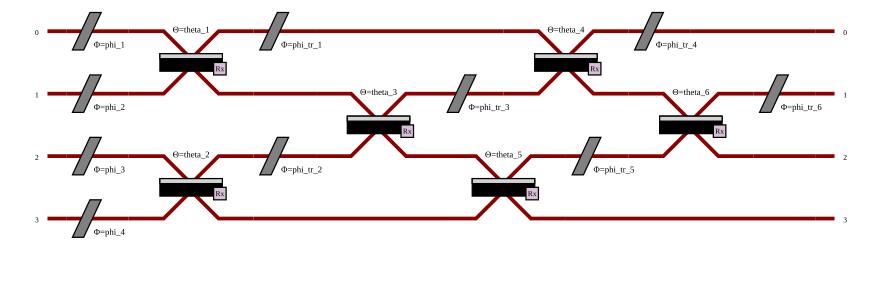

In [11]:
e = pcvl.Circuit(4)

for k in range(4):
    e.add(k, pcvl.PS(P(f"phi_{k+1}")))

# strato 1
e.add(0, pcvl.BS(theta=P("theta_1")));  e.add(0, pcvl.PS(P("phi_tr_1")))
e.add(2, pcvl.BS(theta=P("theta_2")));  e.add(2, pcvl.PS(P("phi_tr_2")))

# strato 2
e.add(1, pcvl.BS(theta=P("theta_3")));  e.add(1, pcvl.PS(P("phi_tr_3")))

# strato 3
e.add(0, pcvl.BS(theta=P("theta_4")));  e.add(0, pcvl.PS(P("phi_tr_4")))
e.add(2, pcvl.BS(theta=P("theta_5")));  e.add(2, pcvl.PS(P("phi_tr_5")))

# strato 4
e.add(1, pcvl.BS(theta=P("theta_6")));  e.add(1, pcvl.PS(P("phi_tr_6")))

print(len(e.get_parameters()), "parametri liberi")

pcvl.pdisplay_to_file(e, "circuito_4_modi.pdf")
pcvl.pdisplay(e)

In [12]:
for p in e.get_parameters():
    p.set_value(np.pi/2 if p.name.startswith("theta") else 0.0)

U4 = e.compute_unitary()
pcvl.pdisplay(U4, precision=1e-3)
pcvl.pdisplay(probabilita(U4))

U4n = np.array(U4)
print("scarto da I:", np.max(np.abs(U4n.conj().T @ U4n - np.eye(4))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

scarto da I: 4.440892098500626e-16
